# Proyecto Parcial I: Predicción del rendimiento académico con aprendizaje automático
**Universidad de Guayaquil — Carrera de Ciencia de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 | **Grupo:** E | **Fecha:** 25 de noviembre de 2026

**Integrantes:**
- Granda Zambrano Cecilia Lorena
- Almeida Terry
- Campoverde María Fernanda
- Molina Sarco Juan
- Núñez Katherine

**Dataset:** Student Performance, Matemáticas (`student-mat.csv`), Cortez y Silva (2008).

**Preguntas:** (1) ¿Qué nota final obtendrá un estudiante? (2) ¿Aprobará o reprobará?

---
**Archivo independiente:** Parte1 EDA

In [1]:
# Librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
import statsmodels.api as sm

SEED = 2026  # semilla del grupo (justificación en la Parte 2.5)

In [2]:
# Carga del dataset: funciona en Google Colab, en el PC, en GitHub Codespaces y en GitHub Actions
ARCHIVO = 'student-mat.csv'
rutas = [ARCHIVO, os.path.join('data', ARCHIVO)]
ruta = next((r for r in rutas if os.path.exists(r)), None)

if ruta is None:
    try:                      # solo existe en Google Colab
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Copie {ARCHIVO} en la misma carpeta del notebook.')
    print(f'Seleccione el archivo {ARCHIVO}')
    subido = files.upload()
    ruta = next(iter(subido))

df = pd.read_csv(ruta, sep=None, engine='python')  # detecta separador ',' o ';'
assert df.shape[1] == 33, 'El archivo no es el student-mat.csv esperado (33 columnas).'
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## Parte 1. Análisis exploratorio (EDA)
### 1.1 Carga y estructura

In [3]:
# 1.1 Estructura del dataset
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')
print(f'Numéricas ({len(num_cols)}): {num_cols}')
print(f'Categóricas ({len(cat_cols)}): {cat_cols}')
df.info()
display(df.describe().T.round(2))
display(df[cat_cols].describe().T)

Filas: 395 | Columnas: 33
Numéricas (16): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
Categóricas (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guard

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


### 1.2 Distribuciones

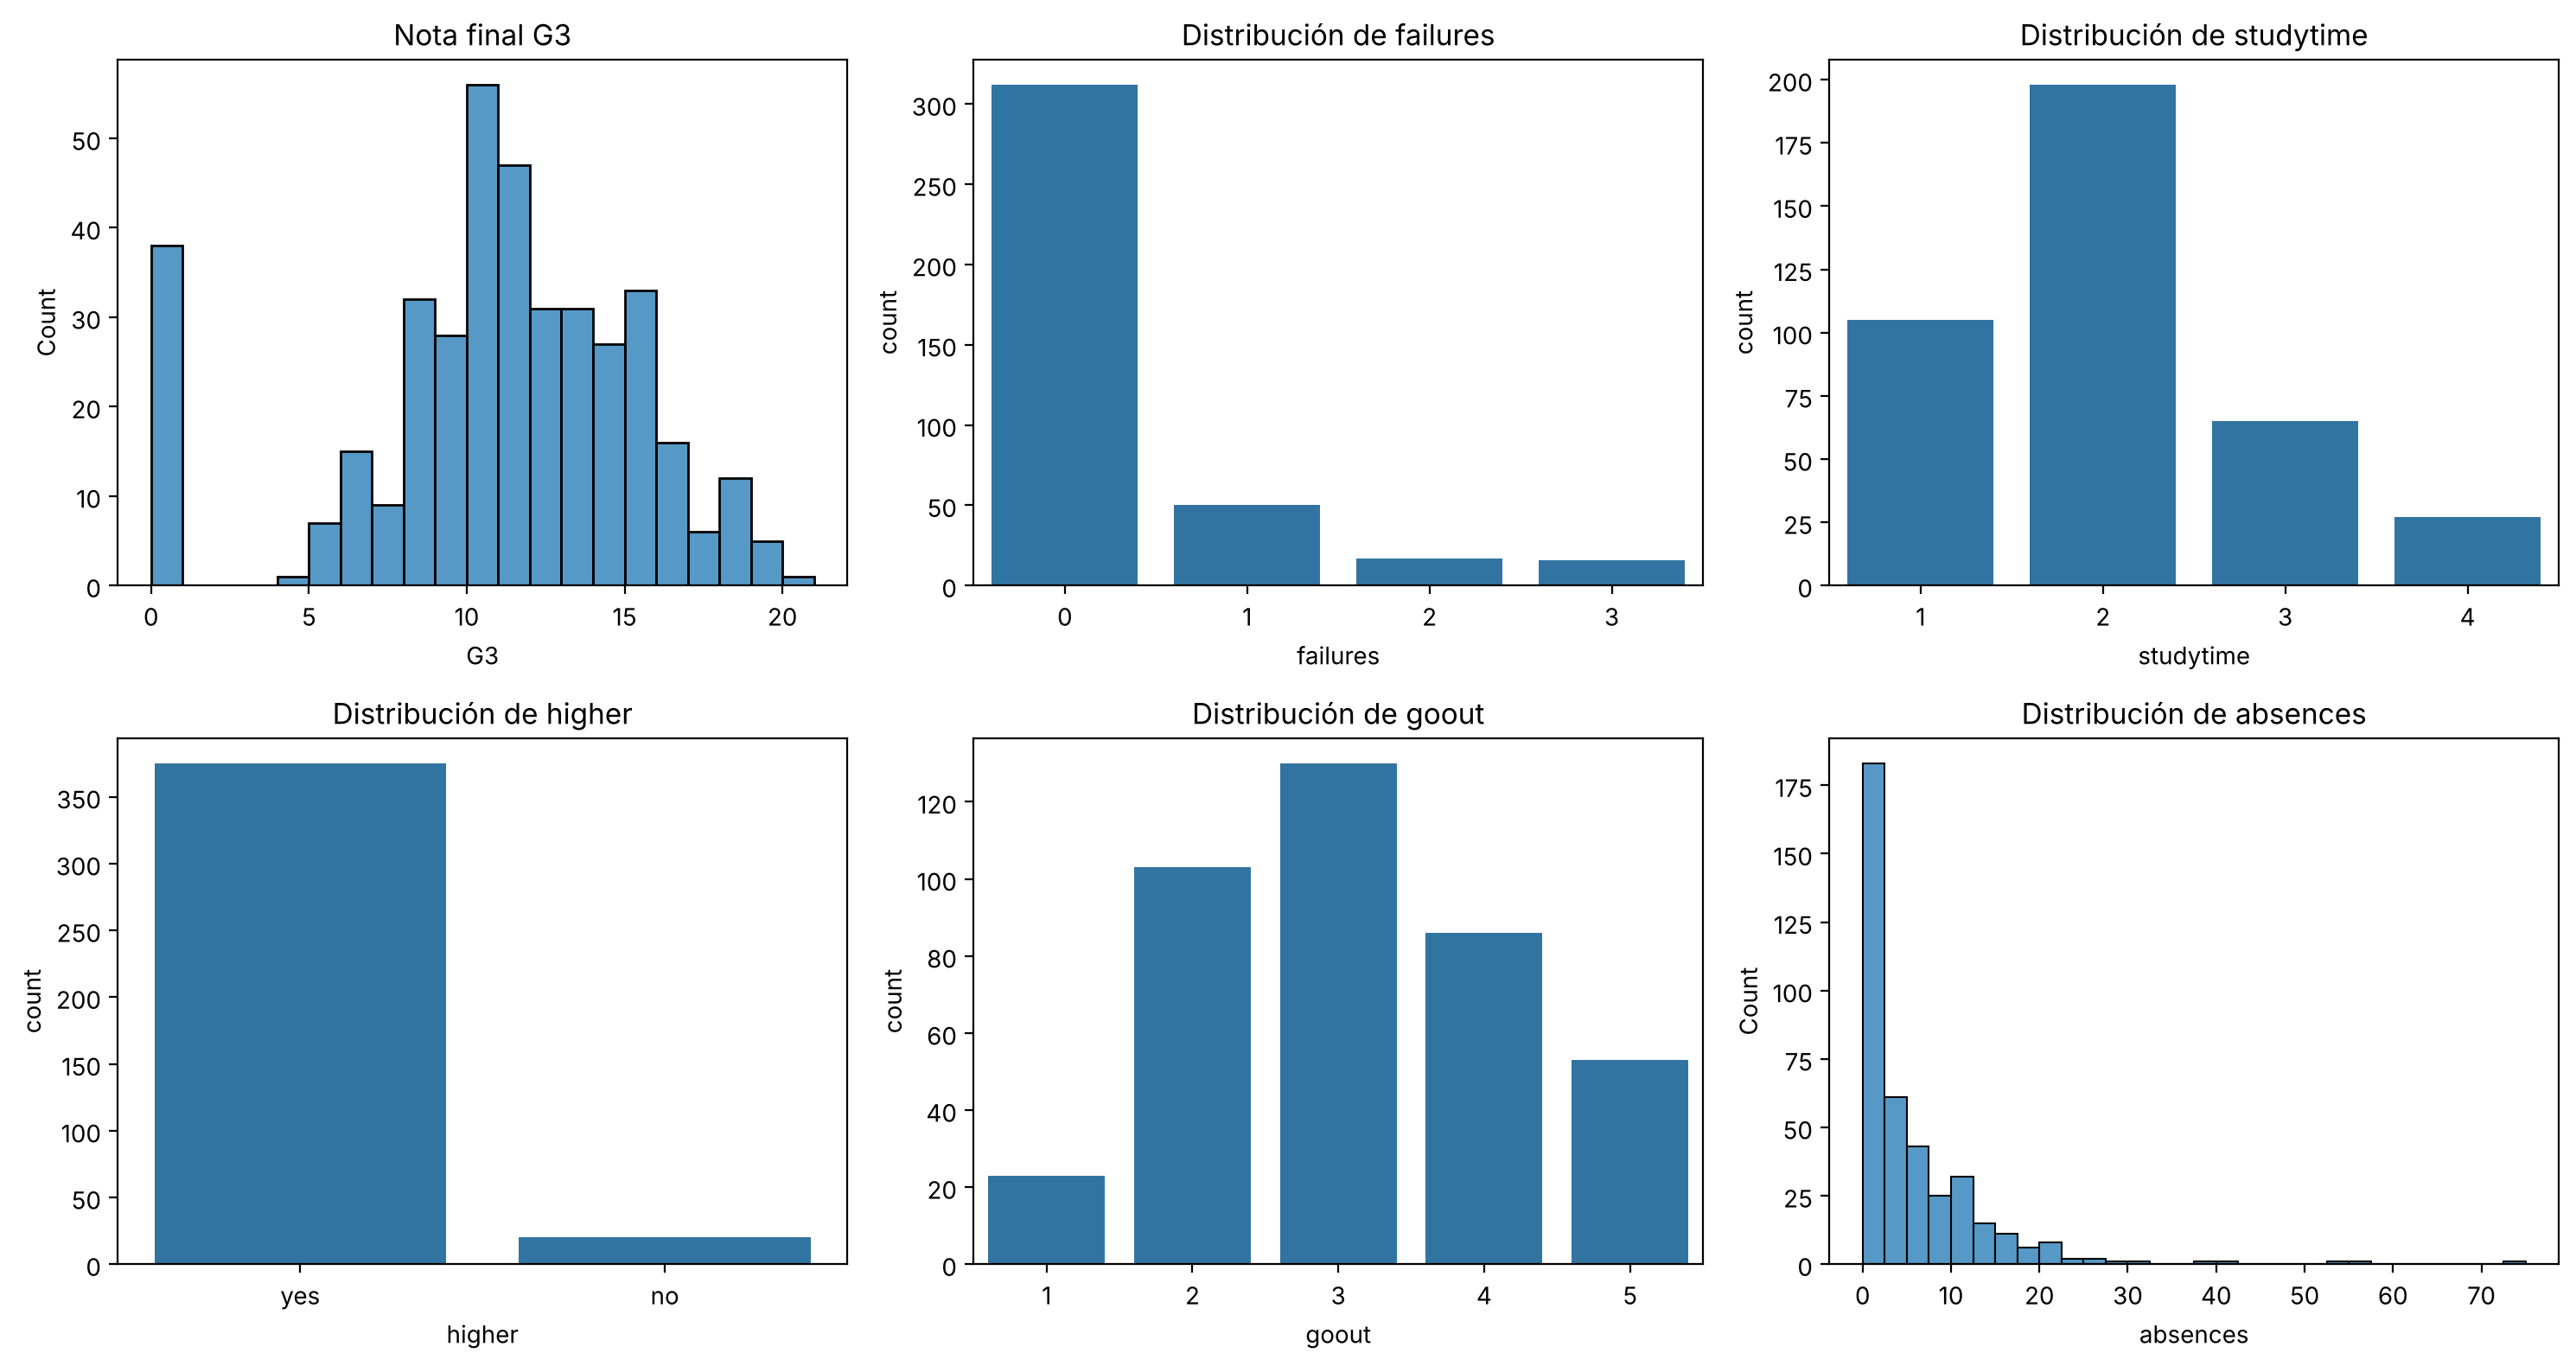

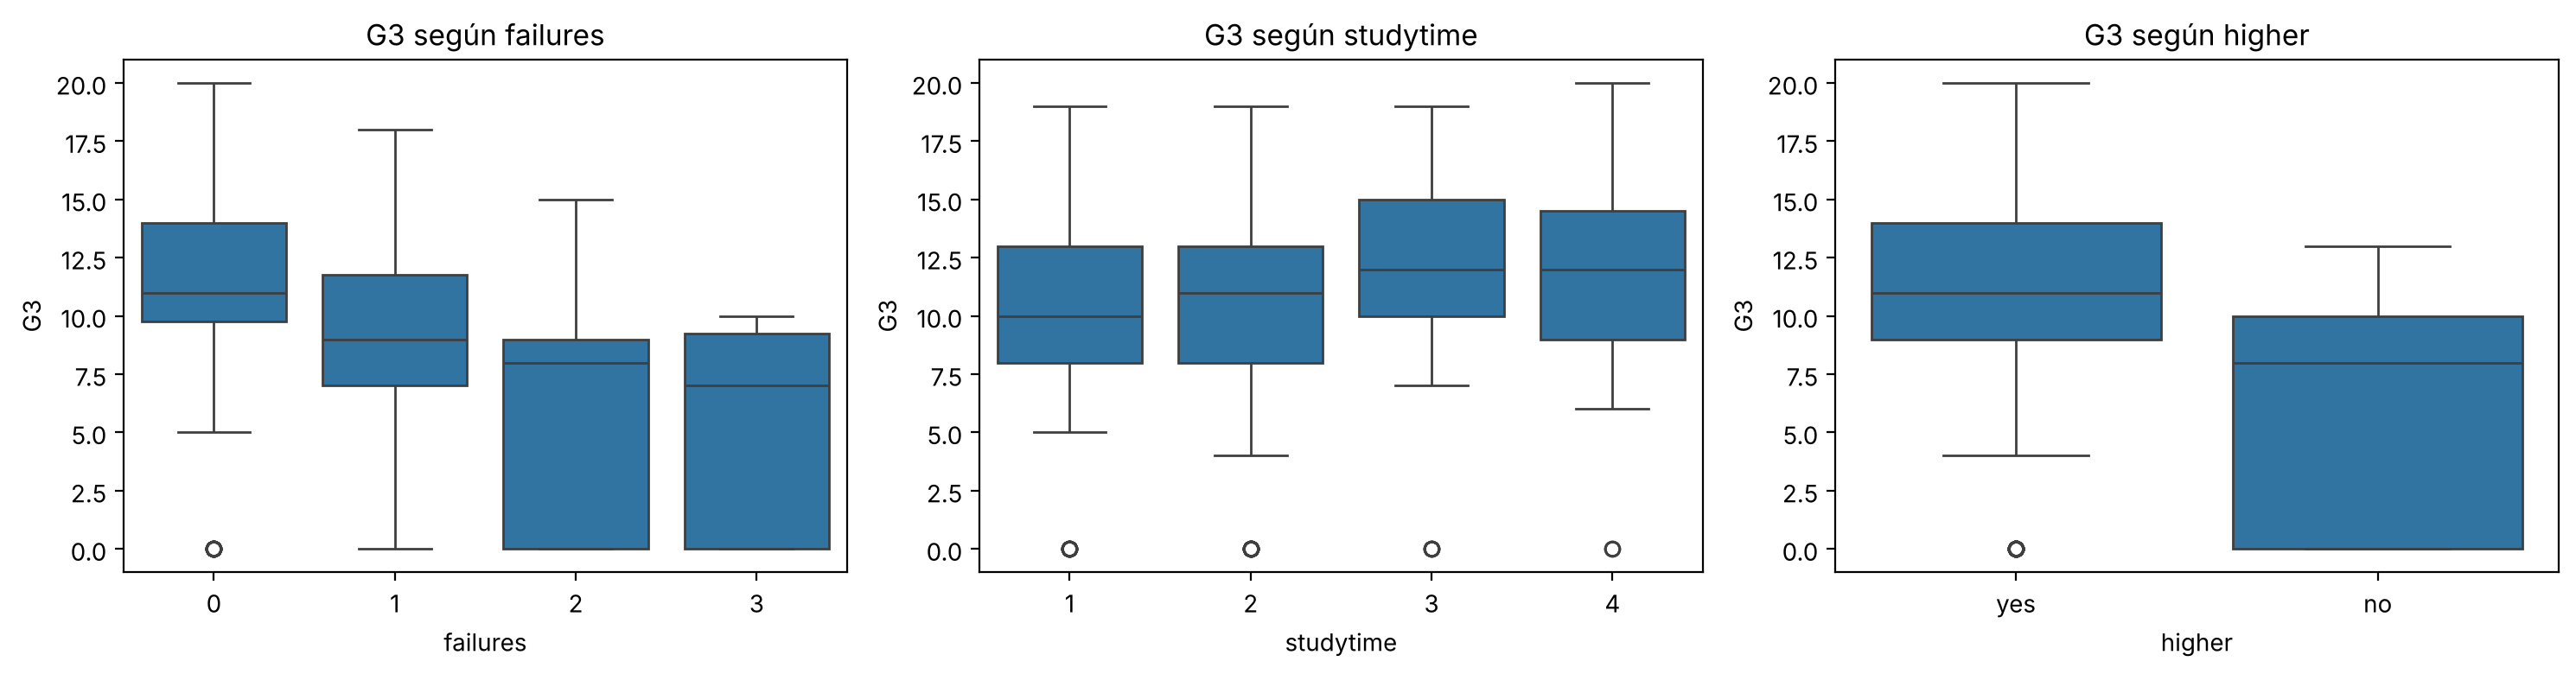

In [4]:
# 1.2 Distribución de G3 y de cuatro variables relevantes
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(df['G3'], bins=range(0, 22), ax=ax[0, 0]); ax[0, 0].set_title('Nota final G3')
for a, v in zip(ax.flat[1:], ['failures', 'studytime', 'higher', 'goout']):
    sns.countplot(x=df[v], ax=a); a.set_title(f'Distribución de {v}')
sns.histplot(df['absences'], bins=30, ax=ax[1, 2]); ax[1, 2].set_title('Distribución de absences')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v in zip(ax, ['failures', 'studytime', 'higher']):
    sns.boxplot(data=df, x=v, y='G3', ax=a); a.set_title(f'G3 según {v}')
plt.tight_layout(); plt.show()

La nota G3 se concentra entre 8 y 14, pero hay un grupo separado con nota 0. La mayoría no tiene reprobaciones previas, estudia 5 horas semanales o menos (niveles 1 y 2) y desea cursar estudios superiores. `absences` tiene una fuerte asimetría a la derecha.

### 1.3 Correlaciones

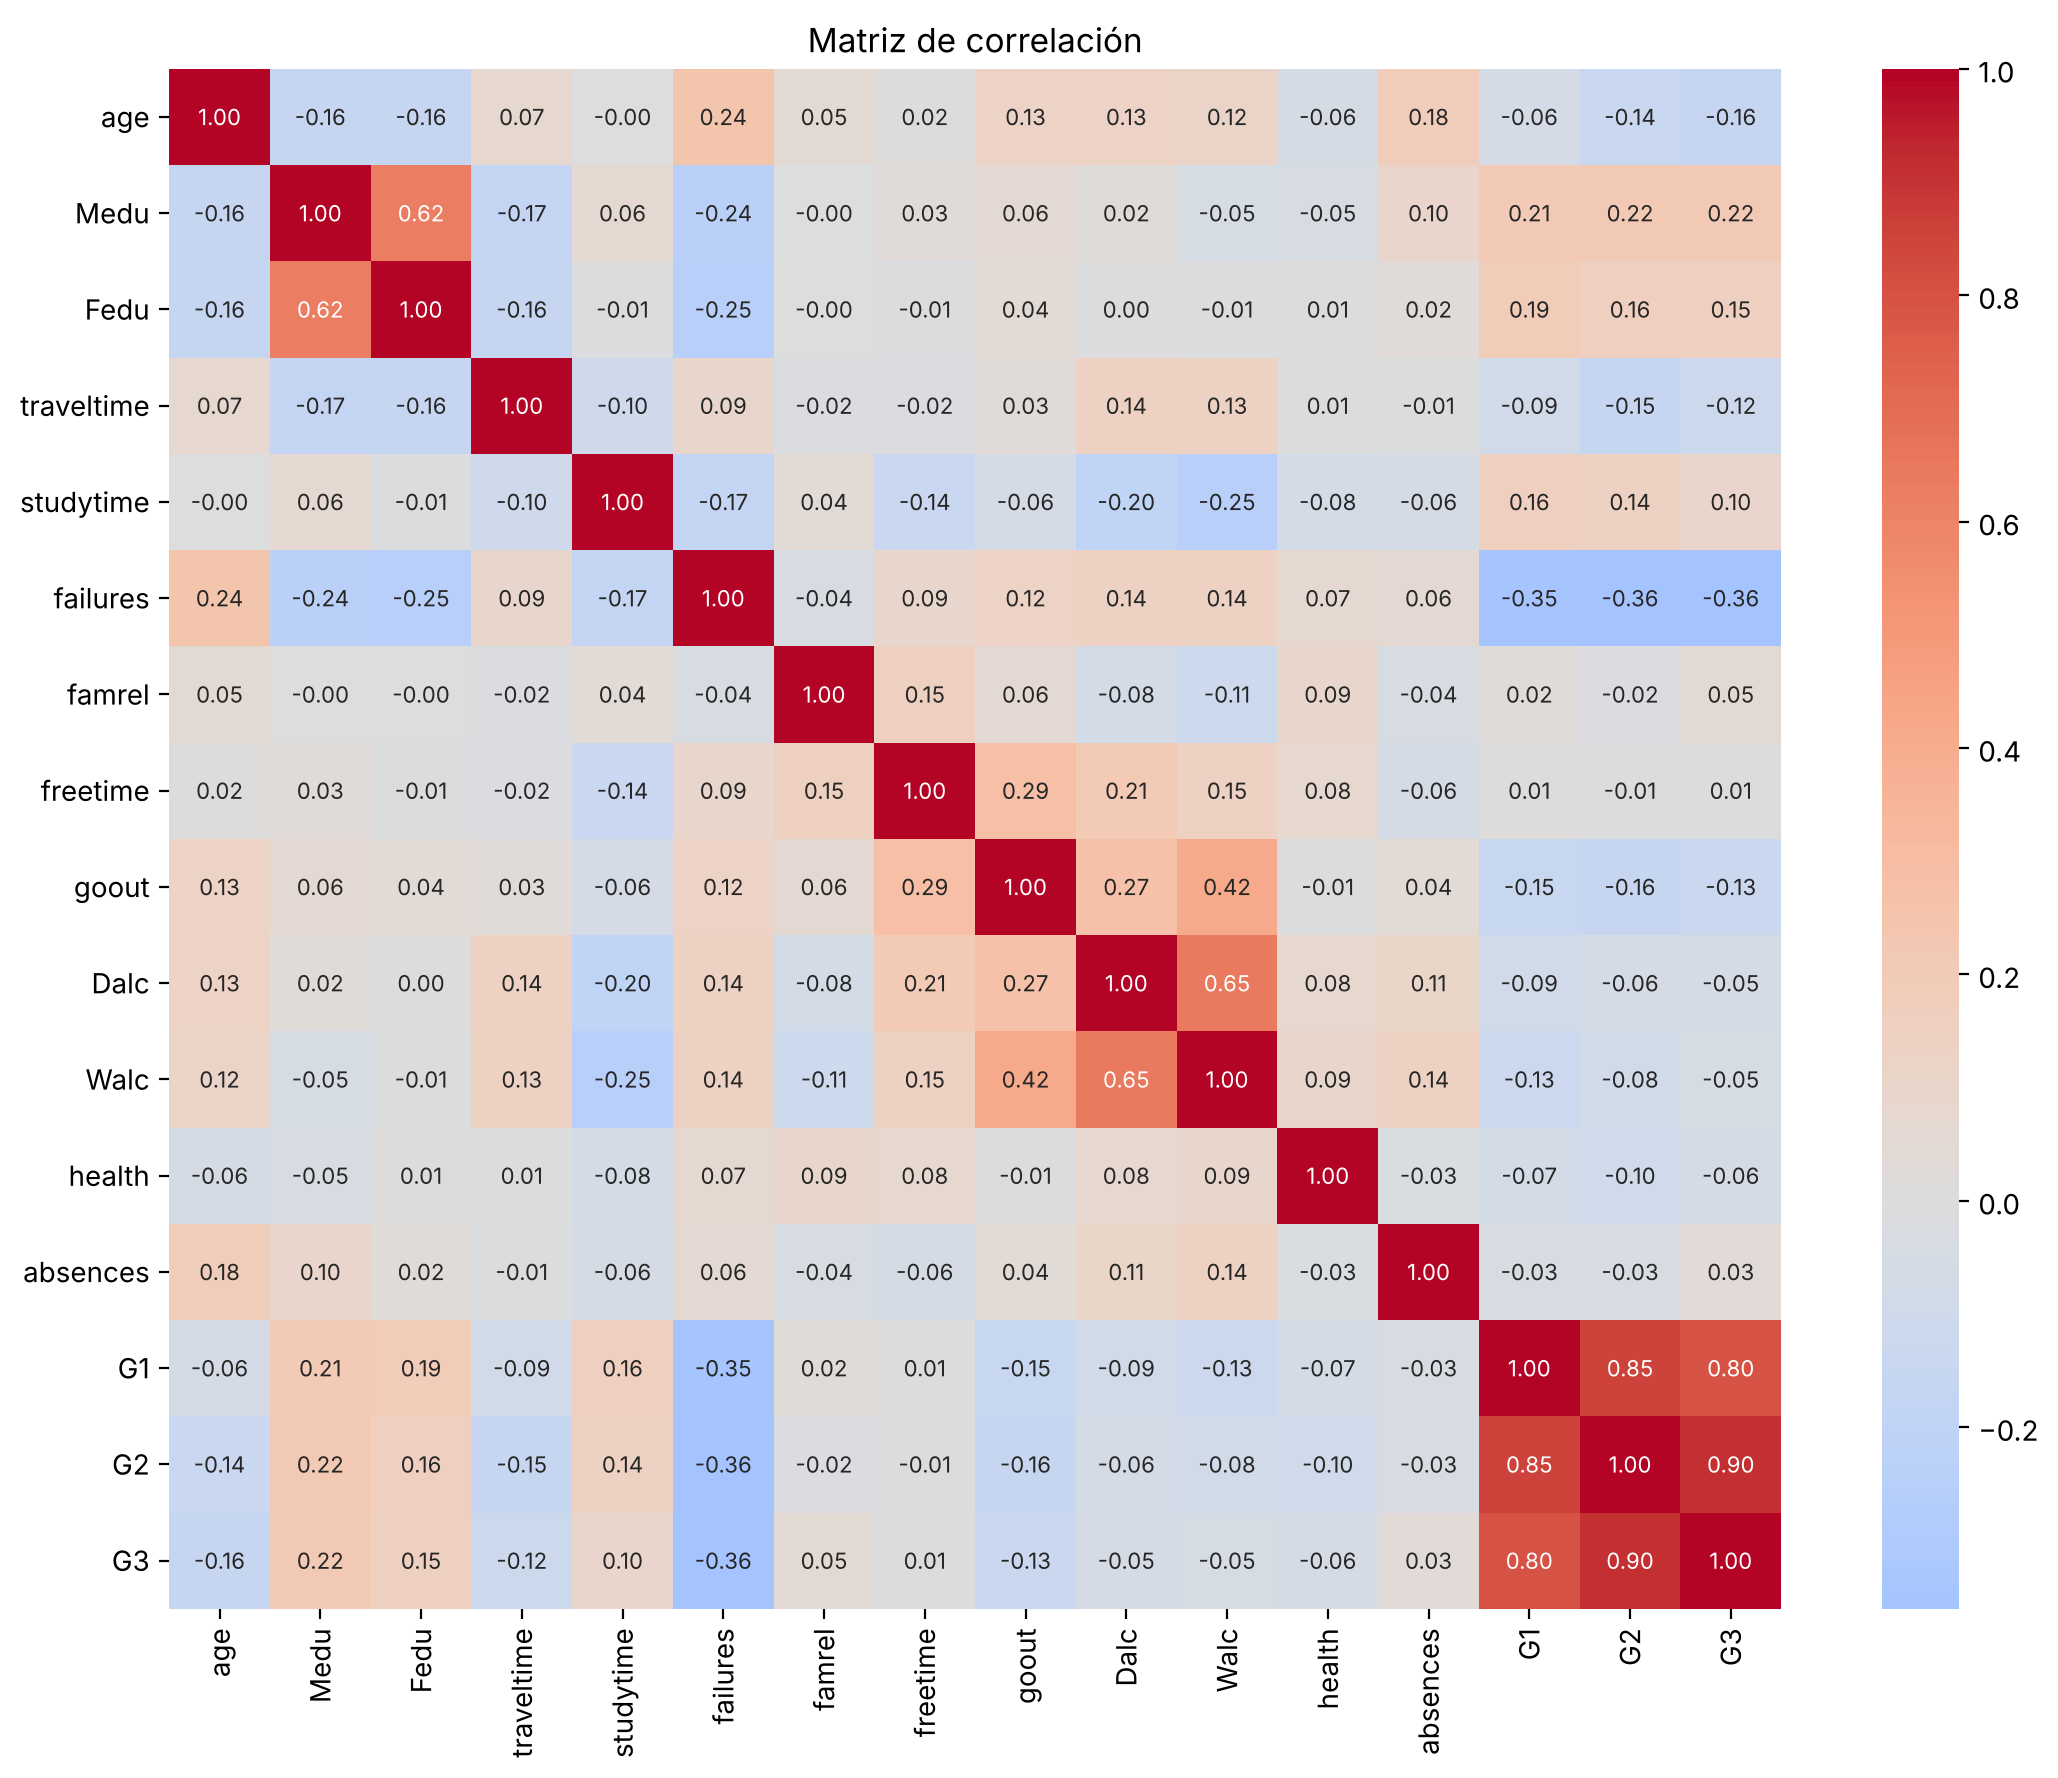

Correlación con G3 (ordenada por valor absoluto):
G2            0.905
G1            0.801
failures     -0.360
Medu          0.217
age          -0.162
Fedu          0.152
goout        -0.133
traveltime   -0.117
studytime     0.098
health       -0.061
Dalc         -0.055
Walc         -0.052
famrel        0.051
absences      0.034
freetime      0.011


In [5]:
# 1.3 Matriz de correlación (Pearson) de todas las variables numéricas
corr = df[num_cols].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Matriz de correlación'); plt.show()

ranking = corr['G3'].drop('G3').sort_values(key=abs, ascending=False)
print('Correlación con G3 (ordenada por valor absoluto):')
print(ranking.round(3).to_string())

Las variables más relacionadas con G3 son **G2 (0.905)** y **G1 (0.801)**. Sin contar las notas, destacan **failures (-0.360)**, **Medu (0.217)**, **age (-0.162)** y **Fedu (0.152)**. Pearson solo mide relación lineal y no implica causalidad.

### 1.4 Hallazgos

In [6]:
# 1.4 Cifras que respaldan los hallazgos
for v in ['failures', 'higher', 'studytime']:
    print(df.groupby(v)['G3'].agg(['count', 'mean']).round(2), '\n')
sin = df.loc[df.failures == 0, 'G3'].mean(); con = df.loc[df.failures > 0, 'G3'].mean()
print(f'Sin reprobaciones: {sin:.2f} | Con reprobaciones: {con:.2f} | Diferencia: {sin-con:.2f}')
print('Estudiantes con G3 = 0:', (df.G3 == 0).sum())
print('Ausencias de quienes tienen G3 = 0:', df.loc[df.G3 == 0, 'absences'].unique())
print(f"Correlación absences-G3 sin los G3 = 0: {df[df.G3 > 0][['absences', 'G3']].corr().iloc[0, 1]:.3f}")

          count   mean
failures              
0           312  11.25
1            50   8.12
2            17   6.24
3            16   5.69 

        count   mean
higher              
no         20   6.80
yes       375  10.61 

           count   mean
studytime              
1            105  10.05
2            198  10.17
3             65  11.40
4             27  11.26 

Sin reprobaciones: 11.25 | Con reprobaciones: 7.27 | Diferencia: 3.99
Estudiantes con G3 = 0: 38
Ausencias de quienes tienen G3 = 0: [0]
Correlación absences-G3 sin los G3 = 0: -0.213


1. **Reprobaciones previas:** quienes tienen al menos una obtienen en promedio **3.99 puntos menos** en G3 (7.27 frente a 11.25). La media baja a medida que aumentan las reprobaciones.
2. **Aspiración de estudios superiores:** quienes desean continuar promedian 10.61 y quienes no, 6.80. El segundo grupo tiene solo 20 estudiantes, por lo que se debe interpretar con cautela.
3. **Notas en cero y ausencias:** hay 38 estudiantes con G3 = 0 y todos registran 0 ausencias. Podría deberse a abandono o a no rendir la evaluación, pero el dataset no lo aclara. Estos casos distorsionan la relación: la correlación entre ausencias y G3 cambia al excluirlos (ver salida anterior).

## Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)* (pp. 5–12). EUROSIS.

> **Pendiente del grupo:** agregar en APA 7 las fuentes que realmente hayan consultado en la biblioteca de la Universidad.

## Declaración de uso de inteligencia artificial
Se utilizó Claude (Anthropic) para revisar el notebook frente a la guía, corregir y completar el código, ejecutarlo y redactar un borrador de las interpretaciones y conclusiones. El grupo debe revisar el contenido, redactar las respuestas con sus propias palabras y poder explicar cada línea en la defensa.